# Entrega 2: Descripción del dataset y origen
**Proyecto:** ¿Qué tan pronto se puede saber quién llega a los playoffs de la NFL?
**Materia:** Aprendizaje Automático, Centro Politécnico Superior Malvinas Argentinas  |  **Alumno:** Tomás Roa Gunn

Este notebook hace todo lo necesario **antes de entrenar modelos**: carga del dato crudo, descripción, limpieza, construcción de la variable objetivo, construcción de las variables por corte de temporada (con control de filtración de información), exploración y diseño de la validación.

El documento con la descripción completa y el origen está en `docs/descripcion_dataset_y_origen.md`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nfl_playoffs.config import CORTES, FIGURAS, INTERIM, PROCESSED, RAW, TEMPORADA_MAX, TEMPORADA_MIN
from nfl_playoffs.features import cargar_partidos, equipos_a_playoffs, partidos_por_equipo, tabla_corte

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Dato crudo (`data/raw/games.csv`)

In [2]:
raw = pd.read_csv(RAW / "games.csv")
print("Filas (partidos):", raw.shape[0], "| Columnas:", raw.shape[1])
print("Temporadas:", raw.season.min(), "a", raw.season.max())
print("\nTipos de dato:", raw.dtypes.astype(str).value_counts().to_dict())
print("\nPartidos por tipo (REG = temporada regular; WC, DIV, CON, SB = playoffs):")
print(raw.game_type.value_counts().to_dict())
raw[["game_id", "season", "game_type", "week", "gameday", "away_team", "away_score", "home_team", "home_score", "result", "div_game"]].head()

Filas (partidos): 7548 | Columnas: 46
Temporadas: 1999 a 2026

Tipos de dato: {'str': 21, 'float64': 18, 'int64': 7}

Partidos por tipo (REG = temporada regular; WC, DIV, CON, SB = playoffs):
{'REG': 7239, 'WC': 120, 'DIV': 108, 'CON': 54, 'SB': 27}


,game_id,season,game_type,week,gameday,away_team,away_score,home_team,home_score,result,div_game
0,1999_01_MIN_ATL,1999,REG,1,1999-09-12,MIN,17.0,ATL,14.0,-3.0,0
1,1999_01_KC_CHI,1999,REG,1,1999-09-12,KC,17.0,CHI,20.0,3.0,0
2,1999_01_PIT_CLE,1999,REG,1,1999-09-12,PIT,43.0,CLE,0.0,-43.0,1
3,1999_01_OAK_GB,1999,REG,1,1999-09-12,OAK,24.0,GB,28.0,4.0,0
4,1999_01_BUF_IND,1999,REG,1,1999-09-12,BUF,14.0,IND,31.0,17.0,1


In [3]:
# Valores faltantes: solo columnas con algún faltante
faltantes = raw.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("faltantes")
faltantes["% del total"] = (faltantes.faltantes / len(raw) * 100).round(1)
faltantes.sort_values("faltantes", ascending=False)

,faltantes,% del total
nfl_detail_id,7276,96.4
ftn,5602,74.2
pff,2879,38.1
temp,2297,30.4
wind,2297,30.4
under_odds,2120,28.1
over_odds,2120,28.1
away_moneyline,2117,28.0
home_moneyline,2117,28.0
away_spread_odds,2117,28.0


Las columnas con muchos faltantes (cuotas de apuestas, ids de otras fuentes, clima) **no se usan** en este proyecto: las variables salen solo de los resultados de los partidos. Las que sí se usan (`season`, `game_type`, `week`, `gameday`, equipos y puntajes) hay que revisarlas con cuidado.

In [4]:
# ¿Hay partidos sin jugar? El archivo también trae el calendario de la temporada en curso (2026)
sin_jugar = raw[raw.home_score.isna()]
print("Partidos sin puntaje:", len(sin_jugar), "| temporadas:", sorted(sin_jugar.season.unique()))
print("Partidos 2026 con puntaje (ya jugados):", int(raw[raw.season == 2026].home_score.notna().sum()), "de", int((raw.season == 2026).sum()))

Partidos sin puntaje: 152 | temporadas: [np.int64(2026)]
Partidos 2026 con puntaje (ya jugados): 120 de 272


**Hallazgo:** el archivo incluye la temporada **2026, que todavía está en curso**: el calendario completo, con puntajes solo en los partidos ya jugados. No sirve para predecir porque todavía no sabemos quién llega a playoffs, así que se **excluye**.

## 2. Alcance: qué temporadas y partidos se usan

In [5]:
g = cargar_partidos()
print(f"Temporadas usadas: {TEMPORADA_MIN} a {TEMPORADA_MAX} -> {g.season.nunique()} temporadas, {len(g)} partidos jugados")
print("Equipos distintos (tras unificar mudanzas OAK->LV, SD->LAC, STL->LA):", len(set(g.home_team) | set(g.away_team)))
reg = g[g.game_type == "REG"].groupby("season").size()
print("\nPartidos de temporada regular por año:", reg.to_dict())

Temporadas usadas: 2002 a 2025 -> 24 temporadas, 6499 partidos jugados
Equipos distintos (tras unificar mudanzas OAK->LV, SD->LAC, STL->LA): 32

Partidos de temporada regular por año: {2002: 256, 2003: 256, 2004: 256, 2005: 256, 2006: 256, 2007: 256, 2008: 256, 2009: 256, 2010: 256, 2011: 256, 2012: 256, 2013: 256, 2014: 256, 2015: 256, 2016: 256, 2017: 256, 2018: 256, 2019: 256, 2020: 256, 2021: 272, 2022: 271, 2023: 272, 2024: 272, 2025: 272}


- Se usa **desde 2002**, cuando la liga pasa a 32 equipos y la estructura de divisiones se estabiliza.
- Hay una excepción conocida en **2022**: 271 partidos en lugar de 272, porque el partido Bills–Bengals de la semana 17 se canceló. Buffalo y Cincinnati jugaron 16 partidos esa temporada. Como los cortes llegan hasta 12 partidos, no afecta.
- Las temporadas tienen **16 partidos hasta 2020 y 17 desde 2021**.

## 3. Variable objetivo: `llega_playoffs`

Total de equipo-temporadas en playoffs: 300


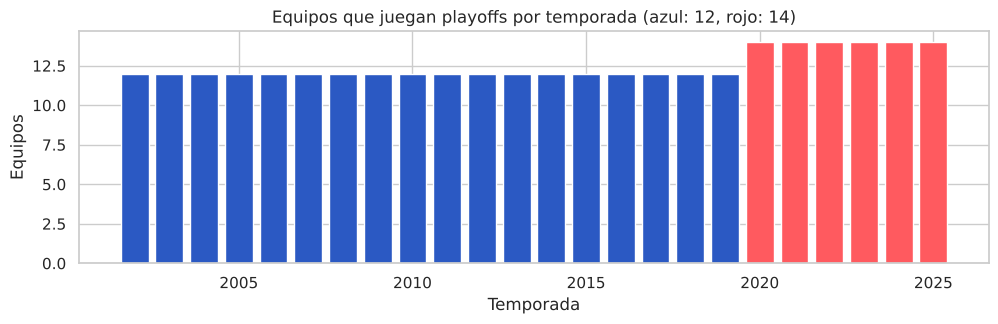

In [6]:
objetivo = equipos_a_playoffs(g)
por_temp = pd.Series([s for s, _ in objetivo]).value_counts().sort_index().rename("equipos_en_playoffs").to_frame()
por_temp["formato"] = np.where(por_temp.index >= 2020, "14 equipos", "12 equipos")
print("Total de equipo-temporadas en playoffs:", len(objetivo))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(por_temp.index, por_temp.equipos_en_playoffs, color=np.where(por_temp.index >= 2020, "#FF5A5F", "#2B59C3"))
ax.set_title("Equipos que juegan playoffs por temporada (azul: 12, rojo: 14)"); ax.set_xlabel("Temporada"); ax.set_ylabel("Equipos")
plt.tight_layout(); plt.savefig(FIGURAS / "equipos_playoffs_por_temporada.png", dpi=150); plt.show()

Un equipo **llega a playoffs** (1) si juega al menos un partido de tipo `WC`, `DIV`, `CON` o `SB` en esa temporada (incluye a los que descansan en la primera ronda). Cambio importante: hasta 2019 clasifican **12 equipos**, desde 2020 **14**. Eso mueve la proporción de positivos de 37,5 % a 43,8 %.

## 4. Un registro por equipo y partido (`data/interim/partidos_por_equipo.csv`)

In [7]:
tg = partidos_por_equipo(g)
INTERIM.mkdir(parents=True, exist_ok=True)
tg.to_csv(INTERIM / "partidos_por_equipo.csv", index=False)
print(tg.shape)
tg[(tg.season == 2024) & (tg.team == "PIT")].head(6)

(12446, 11)


,season,week,gameday,team,rival,es_local,puntos_favor,puntos_contra,div_game,resultado,n_partido
11800,2024,1,2024-09-08,PIT,ATL,0,18.0,10.0,0,1.0,1
11801,2024,2,2024-09-15,PIT,DEN,0,13.0,6.0,0,1.0,2
11802,2024,3,2024-09-22,PIT,LAC,1,20.0,10.0,0,1.0,3
11803,2024,4,2024-09-29,PIT,IND,0,24.0,27.0,0,0.0,4
11804,2024,5,2024-10-06,PIT,DAL,1,17.0,20.0,0,0.0,5
11805,2024,6,2024-10-13,PIT,LV,0,32.0,13.0,0,1.0,6


Cada partido se convierte en dos filas, una por equipo. `n_partido` es el **número de partido de ese equipo en esa temporada**, ordenado por fecha: así "los primeros 9 partidos" son los 9 que jugó, no la semana 9. Esto importa por la semana de descanso (*bye*): en la semana 9 hay equipos que jugaron 8 partidos. `resultado` vale 1 (victoria), 0,5 (empate) o 0 (derrota).

## 5. Variables por corte de temporada
Para cada corte **N ∈ {4, 6, 9, 12}** se calculan las variables usando **solo los primeros N partidos del equipo**:

| Variable | Qué mide |
|---|---|
| `partidos`, `victorias`, `empates`, `derrotas` | Récord hasta el corte |
| `pct_victorias` | Victorias (los empates cuentan 0,5) sobre partidos jugados |
| `puntos_favor_prom`, `puntos_contra_prom`, `dif_puntos_prom` | Promedios por partido y diferencia |
| `pct_victorias_ult4` | Rendimiento en los últimos 4 partidos del corte (racha) |
| `partidos_local` | Cuántos de esos partidos jugó de local |
| **`llega_playoffs`** | **Variable objetivo** (1 = juega playoffs esa temporada) |

In [8]:
tablas = {n: tabla_corte(tg, objetivo, n) for n in CORTES}
PROCESSED.mkdir(parents=True, exist_ok=True)
for n, t in tablas.items():
    t.to_csv(PROCESSED / f"variables_corte_{n:02d}.csv", index=False)
todos = pd.concat(tablas.values(), ignore_index=True)
todos.to_csv(PROCESSED / "variables_todos_los_cortes.csv", index=False)
print({n: t.shape for n, t in tablas.items()})
tablas[9].head()

{4: (768, 14), 6: (768, 14), 9: (768, 14), 12: (768, 14)}


,season,team,corte,partidos,victorias,empates,derrotas,pct_victorias,puntos_favor_prom,puntos_contra_prom,dif_puntos_prom,pct_victorias_ult4,partidos_local,llega_playoffs
0,2002,ARI,9,9,4,0,5,0.444444,17.333333,20.555556,-3.222222,0.250,5,0
1,2002,ATL,9,9,5,1,3,0.611111,24.555556,18.888889,5.666667,0.875,5,1
2,2002,BAL,9,9,4,0,5,0.444444,19.666667,21.000000,-1.333333,0.500,5,0
3,2002,BUF,9,9,5,0,4,0.555556,27.555556,29.888889,-2.333333,0.750,5,0
4,2002,CAR,9,9,3,0,6,0.333333,15.000000,16.777778,-1.777778,0.000,5,0


### Control de filtración de información (data leakage)

In [9]:
# 1) Cada fila usa exactamente N partidos
for n, t in tablas.items():
    assert (t.partidos == n).all(), f"corte {n}: hay filas con distinta cantidad de partidos"
# 2) No hay faltantes
assert todos.isna().sum().sum() == 0
# 3) Cada temporada tiene 32 equipos, y 12 o 14 en playoffs
chk = tablas[9].groupby("season").agg(equipos=("team", "nunique"), playoffs=("llega_playoffs", "sum"))
assert (chk.equipos == 32).all() and (chk.playoffs == np.where(chk.index >= 2020, 14, 12)).all()
# 4) Recalculo a mano un caso con el dato crudo, usando SOLO partidos hasta la fecha del N-ésimo partido
def recalcular(season, team, n):
    r = g[(g.game_type == "REG") & (g.season == season) & ((g.home_team == team) | (g.away_team == team))].sort_values(["gameday", "week"]).head(n)
    pf = np.where(r.home_team == team, r.home_score, r.away_score)
    pc = np.where(r.home_team == team, r.away_score, r.home_score)
    res = np.where(pf > pc, 1.0, np.where(pf < pc, 0.0, 0.5))
    return res.mean(), pf.mean(), pc.mean()
rng = np.random.default_rng(42)
for _ in range(200):
    s, t = rng.choice(np.arange(2002, 2026)), rng.choice(sorted(set(g.home_team)))
    n = rng.choice(CORTES)
    fila = tablas[n].query("season == @s and team == @t").iloc[0]
    pv, pf, pc = recalcular(s, t, n)
    assert np.isclose(fila.pct_victorias, pv) and np.isclose(fila.puntos_favor_prom, pf) and np.isclose(fila.puntos_contra_prom, pc)
print("OK: 200 casos al azar coinciden con el recálculo manual; todas las filas usan solo N partidos.")

OK: 200 casos al azar coinciden con el recálculo manual; todas las filas usan solo N partidos.


Estos controles confirman que las variables de cada corte **no incluyen ningún partido posterior** al N-ésimo, y que la variable objetivo tiene la cantidad esperada de equipos por temporada. Otras decisiones para evitar filtración:
- **No se usa `season` como variable** (el modelo no debe aprender el año).
- **No se usan** `result`, `total` ni cuotas/spreads del partido: son del partido en sí, o dependen de información externa.
- El **escalado se hará dentro de un `Pipeline`**, ajustado solo con los datos de entrenamiento de cada partición (entrega 3).

## 6. Exploración

In [10]:
print("Equipos en playoffs sobre el total (cada corte tiene las mismas 768 filas):")
bal = todos.groupby("corte").llega_playoffs.agg(filas="count", playoffs="sum", proporcion="mean").round(3)
bal

Equipos en playoffs sobre el total (cada corte tiene las mismas 768 filas):


,filas,playoffs,proporcion
corte,,,
4,768,300,0.391
6,768,300,0.391
9,768,300,0.391
12,768,300,0.391


In [11]:
vars_num = ["pct_victorias", "dif_puntos_prom", "puntos_favor_prom", "puntos_contra_prom", "pct_victorias_ult4", "partidos_local"]
tablas[9][vars_num + ["llega_playoffs"]].groupby("llega_playoffs").agg(["mean", "std"]).round(2).T

llega_playoffs               0      1
pct_victorias      mean   0.39   0.68
                   std    0.17   0.15
dif_puntos_prom    mean  -3.41   5.30
                   std    5.54   4.81
puntos_favor_prom  mean  20.46  25.39
                   std    4.25   4.15
puntos_contra_prom mean  23.88  20.10
                   std    3.84   3.35
pct_victorias_ult4 mean   0.38   0.68
                   std    0.24   0.24
partidos_local     mean   4.49   4.51
                   std    0.56   0.57

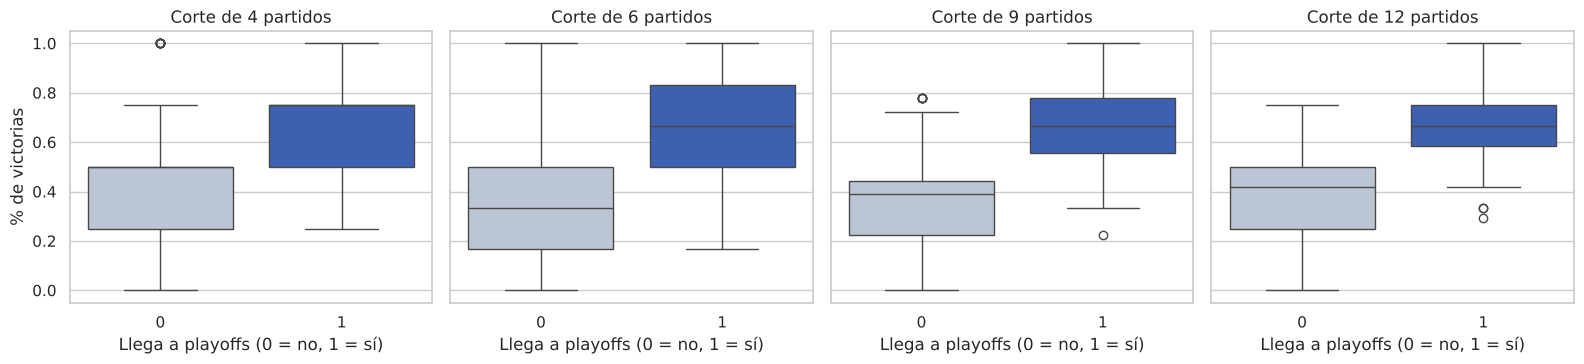

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, n in zip(axes, CORTES):
    sns.boxplot(data=tablas[n], x="llega_playoffs", y="pct_victorias", hue="llega_playoffs", palette=["#B8C4D8", "#2B59C3"], legend=False, ax=ax)
    ax.set_title(f"Corte de {n} partidos"); ax.set_xlabel("Llega a playoffs (0 = no, 1 = sí)"); ax.set_ylabel("% de victorias" if n == 4 else "")
plt.tight_layout(); plt.savefig(FIGURAS / "pct_victorias_por_corte.png", dpi=150); plt.show()

In [13]:
# ¿Cuánto separa el % de victorias a los clasificados de los no clasificados, según el corte?
from sklearn.metrics import roc_auc_score
filas = []
for n, d in todos.groupby("corte"):
    a, b = d[d.llega_playoffs == 1].pct_victorias, d[d.llega_playoffs == 0].pct_victorias
    d_cohen = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    filas.append({"corte": n, "prom_no_llega": b.mean(), "prom_llega": a.mean(), "diferencia": a.mean() - b.mean(),
                  "desvio_dentro_grupo": np.sqrt((a.var() + b.var()) / 2), "separacion_estandarizada": d_cohen,
                  "AUC_solo_pct_victorias": roc_auc_score(d.llega_playoffs, d.pct_victorias)})
pd.DataFrame(filas).set_index("corte").round(3)

,prom_no_llega,prom_llega,diferencia,desvio_dentro_grupo,separacion_estandarizada,AUC_solo_pct_victorias
corte,,,,,,
4,0.389,0.679,0.290,0.231,1.257,0.798
6,0.391,0.675,0.284,0.191,1.491,0.845
9,0.385,0.679,0.294,0.157,1.875,0.902
12,0.381,0.684,0.303,0.142,2.138,0.933


**Lectura (descriptiva, sin modelos):** la diferencia entre los promedios casi no cambia con el corte (alrededor de 0,29 a 0,30), pero la **dispersión dentro de cada grupo baja** al haber más partidos, así que los dos grupos se **solapan menos**: la separación estandarizada pasa de ~1,3 (4 partidos) a ~2,1 (12 partidos). Mirado con un solo indicador, el % de victorias ordena bien a los equipos (AUC de 0,80 con 4 partidos a 0,93 con 12).

Esto es una **hipótesis para la Entrega 3**, no un resultado: se calculó con todas las temporadas, incluidas 2019–2025, así que **no se usa para elegir modelos ni cortes**.

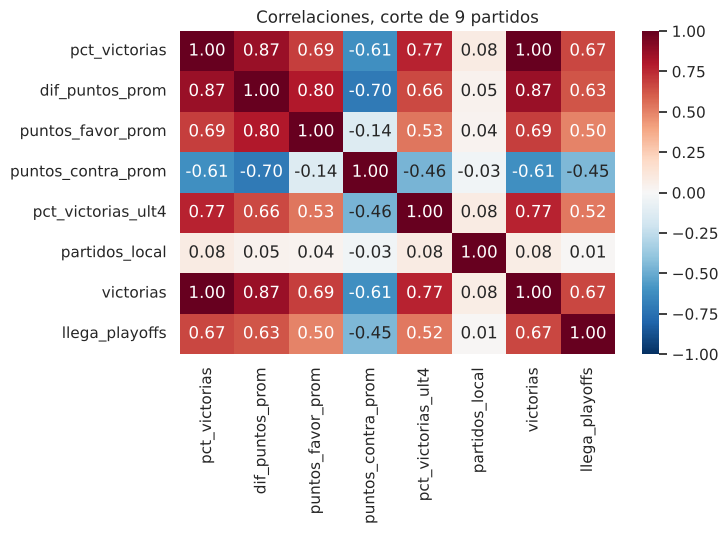

In [14]:
plt.figure(figsize=(7.5, 5.5))
corr = tablas[9][vars_num + ["victorias", "llega_playoffs"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlaciones, corte de 9 partidos"); plt.tight_layout()
plt.savefig(FIGURAS / "correlaciones_corte_09.png", dpi=150); plt.show()

`victorias` y `pct_victorias` son **la misma variable** dentro de cada corte (todos los equipos tienen N partidos; correlación 1,00), y `dif_puntos_prom` está muy correlacionada con ellas (~0,87). Para los modelos lineales conviene no usarlas todas juntas, o regularizar. Además, en el corte de **4 partidos** `pct_victorias_ult4` es idéntica a `pct_victorias` (los últimos 4 son todos los partidos del corte), así que se descarta en ese corte. Se decide en la Entrega 3.

In [15]:
# Valores atípicos y rangos de las variables (corte 9)
tablas[9][vars_num].describe().round(2)

,pct_victorias,dif_puntos_prom,puntos_favor_prom,puntos_contra_prom,pct_victorias_ult4,partidos_local
count,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.50,-0.01,22.39,22.40,0.50,4.50
std,0.21,6.77,4.85,4.09,0.28,0.56
min,0.00,-19.56,8.67,10.89,0.00,3.00
25%,0.33,-4.44,18.97,19.33,0.25,4.00
50%,0.44,-0.22,22.33,22.22,0.50,4.00
75%,0.67,4.89,25.58,25.33,0.75,5.00
max,1.00,23.11,41.22,34.22,1.00,6.00


## 7. Diseño de la validación (recoge los comentarios de la Entrega 1)
**Problema:** el conjunto 2019–2025 ya se usó como prueba en la Semana 6, así que no es una prueba independiente.

**Decisión:** validación *walk-forward* (ventana creciente): para cada temporada `y` entre 2010 y 2025, se entrena con 2002 hasta `y-1` y se valida en `y`. Así:
- el entrenamiento **siempre es anterior** a la validación (nunca se mezclan temporadas al azar);
- hay 16 tramos de validación, incluidos **9 anteriores a 2019** (2010 a 2018) que nunca se usaron como prueba;
- los tramos 2019 a 2025 se **reportan aparte y se declaran como ya vistos**.

In [16]:
folds = pd.DataFrame({"validacion": range(2010, 2026)})
folds["entrenamiento"] = folds.validacion.map(lambda y: f"{TEMPORADA_MIN}-{y - 1}")
folds["filas_entrenamiento"] = (folds.validacion - TEMPORADA_MIN) * 32
folds["filas_validacion"] = 32
folds["vista_en_semana_6"] = np.where(folds.validacion >= 2019, "sí", "no")
folds

,validacion,entrenamiento,filas_entrenamiento,filas_validacion,vista_en_semana_6
0,2010,2002-2009,256,32,no
1,2011,2002-2010,288,32,no
2,2012,2002-2011,320,32,no
3,2013,2002-2012,352,32,no
4,2014,2002-2013,384,32,no
5,2015,2002-2014,416,32,no
6,2016,2002-2015,448,32,no
7,2017,2002-2016,480,32,no
8,2018,2002-2017,512,32,no
9,2019,2002-2018,544,32,sí


**Reglas de ajuste (entrega 3):**
- Los hiperparámetros se eligen con **validación cruzada temporal** (`TimeSeriesSplit` por temporada) **dentro del entrenamiento** de cada tramo.
- Escalado dentro de un `Pipeline`.
- Se entrena un modelo **por corte** (4, 6, 9 y 12) con el mismo esquema, para compararlos de forma justa.

**Referencias para comparar (a calcular en la Entrega 3):**
1. Modelo que siempre predice la clase mayoritaria ("no llega").
2. **Regla simple por % de victorias:** predice "llega" si `pct_victorias` supera un umbral elegido solo con el entrenamiento de cada tramo.

**Qué significa "predicción confiable" (propuesta a confirmar):** la clase positiva es "llega a playoffs", y se prioriza el **F1 de esa clase**, porque equilibra detectar a los que clasifican (recall) sin marcar de más (precisión). Un corte se considerará **suficiente** si, en promedio de los tramos, su F1 **supera a la regla por % de victorias**, y no solo a la clase mayoritaria. El umbral numérico de "suficiente" se fijará en la Entrega 3 a partir de los resultados del entrenamiento, antes de mirar el período 2019–2025.

## 8. Conclusiones y limitaciones
- **Dataset final:** 768 equipo-temporadas × 4 cortes, con 10 variables numéricas y la variable objetivo; sin faltantes.
- **Proporción de positivos:** 39,1 % en total (37,5 % hasta 2019 y 43,8 % desde 2020), por el cambio de formato.
- **Limitaciones:** las variables salen solo de resultados de partidos (sin lesiones, calidad del mariscal de campo ni dificultad del calendario restante); son 24 temporadas por corte, un dataset chico; los cortes de una misma temporada están correlacionados entre sí; el formato de playoffs cambió en 2020.
- **Siguiente paso (Entrega 3):** entrenar regresión logística, árbol, KNN y SVM por corte con la validación definida arriba.